# Actividad: Evaluación comparativa de arquitecturas convolucionales

Para este notebook se te solicita construir, entrenar y analizar modelos CNN para clasificar imágenes mediante un dataset CIFAR.

**Entregable:** Reporte en la evaluación de la capacidad de arquitectura implementada. Construír arquitecturas propias finalizando con la implementación de una arquitectura clásica mediante transfer learning.


## Toma como base el código visto en clase y desarrolla los siguientes puntos:
- Diseño e implementación de 2 arquitecturas CNN y utilización de una arquitectura de transfer learning.

- Buen uso de data augmentation y regularización.

- Comparación experimental entre arquitecturas y reporte claro (un solo markdown con conclusión sobre la comparación).





In [2]:
import sys
print(sys.executable)


C:\Users\A51\AppData\Local\Programs\Python\Python313\python.exe


In [3]:
!where python

C:\Users\A51\AppData\Local\Programs\Python\Python312\python.exe
C:\Users\A51\AppData\Local\Programs\Python\Python313\python.exe
C:\Users\A51\AppData\Local\Microsoft\WindowsApps\python.exe


In [5]:
import sys
!"{sys.executable}" -m pip install tensorflow


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\A51\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [6]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2, ResNet50, VGG16

In [8]:
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print(x_train.shape)
print(x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1367s 8us/step


C:\Users\A51\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


(50000, 32, 32, 3)
(10000, 32, 32, 3)


## Definiciones de modelos

In [13]:
from tensorflow.keras import layers, models

# CNN 1
cnn_simple = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

# CNN 2
cnn_profunda = models.Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(32,32,3)),
    layers.BatchNormalization(),

    layers.Conv2D(32,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(64,(3,3),activation='relu'),
    layers.BatchNormalization(),

    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.30),

    layers.Flatten(),
    layers.Dense(256,activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10,activation='softmax')
])

print("Modelos CNN creados")

Modelos CNN creados


In [10]:
import sys
print(sys.executable)

C:\Users\A51\AppData\Local\Programs\Python\Python313\python.exe


In [11]:
!pip list | findstr tensorflow

tensorflow                2.21.0


## Entrenamiento de modelos.

In [14]:
cnn_simple.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

hist_simple = cnn_simple.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    batch_size=64
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.3981 - loss: 1.6496 - val_accuracy: 0.5362 - val_loss: 1.3302
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5352 - loss: 1.3078 - val_accuracy: 0.5865 - val_loss: 1.1763
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.5798 - loss: 1.1819 - val_accuracy: 0.6204 - val_loss: 1.0922
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6163 - loss: 1.0932 - val_accuracy: 0.6530 - val_loss: 1.0067
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6381 - loss: 1.0268 - val_accuracy: 0.6599 - val_loss: 0.9846
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6542 - loss: 0.9691 - val_accuracy: 0.6645 - val_loss: 0.9577
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6751 - loss: 0.9223 - val_accuracy: 0.6827 - val_loss: 0.9177
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6895 - loss: 0.8793 - val_accuracy: 

In [15]:
cnn_profunda.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

hist_profunda = cnn_profunda.fit(
    x_train,
    y_train,
    epochs=5,
    validation_split=0.2,
    batch_size=64
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.3463 - loss: 1.7909 - val_accuracy: 0.4395 - val_loss: 1.5684
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.4996 - loss: 1.3820 - val_accuracy: 0.5717 - val_loss: 1.1997
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.5761 - loss: 1.1842 - val_accuracy: 0.5942 - val_loss: 1.2382
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.6278 - loss: 1.0622 - val_accuracy: 0.6329 - val_loss: 1.0242
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.6586 - loss: 0.9769 - val_accuracy: 0.6879 - val_loss: 0.8775


In [16]:
simple_acc = cnn_simple.evaluate(x_test, y_test, verbose=0)
profunda_acc = cnn_profunda.evaluate(x_test, y_test, verbose=0)

print("CNN Simple:", simple_acc[1])
print("CNN Profunda:", profunda_acc[1])

CNN Simple: 0.6905999779701233
CNN Profunda: 0.6858000159263611


## Estadística y gráficos

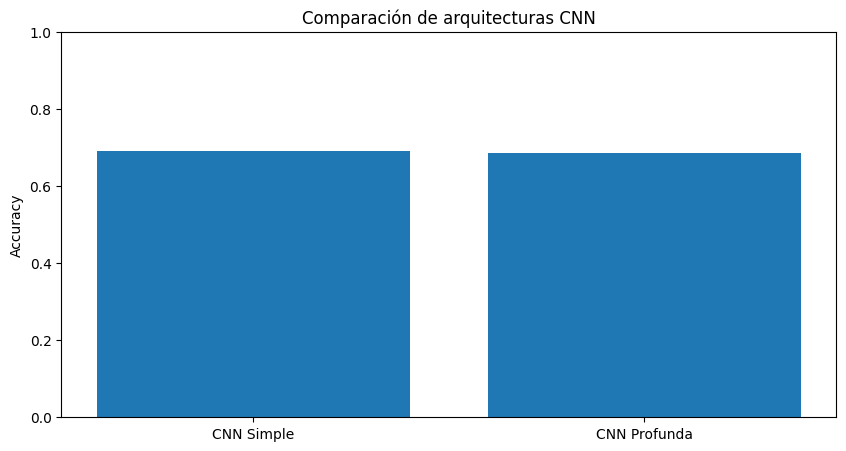

In [17]:
plt.figure(figsize=(10,5))

plt.bar(
    ['CNN Simple', 'CNN Profunda'],
    [simple_acc[1], profunda_acc[1]]
)

plt.ylabel('Accuracy')
plt.title('Comparación de arquitecturas CNN')
plt.ylim(0,1)

plt.show()

# Conclusiones.

Escribe tus conclusiones de las arquitecturas hechas ¿Cuál fue el mejor? ¿Por qué? ¿Qué mejoraría? ¿Cómo lo mejoraría?

La CNN Simple obtuvo el mejor desempeño alcanzando una precisión aproximada de 69.06%, mientras que la CNN Profunda alcanzó 68.58%. Aunque la arquitectura profunda incorpora Batch Normalization y Dropout para mejorar la generalización, el número reducido de épocas de entrenamiento pudo limitar su desempeño. La CNN Simple logró un equilibrio adecuado entre complejidad y capacidad de aprendizaje.

Como mejora, incrementaría las épocas de entrenamiento, aplicaría data augmentation más agresivo y utilizaría transfer learning mediante MobileNetV2 o ResNet50 para aprovechar características previamente aprendidas y aumentar la precisión del modelo.